# Week 3 — Hasil & Analisis (ECG Heartbeat Classification, MIT-BIH)

Analisis eksperimen pembanding terbaik Week 2 (**MobileNetV3-Small + GAF**) terhadap baseline Week 1 (**ResNet18 + GAF**).

| Aturan | Keterangan |
|---|---|
| Sumber data | **Hanya artifact yang sudah ada** (prediksi, history, checkpoint, CSV Week 2). Tidak ada preprocessing ulang, training ulang, atau inferensi ulang. |
| Week 1 / Week 2 | **Hanya dibaca.** Snapshot (ukuran + mtime) dibuat di Section 3 dan dicek ulang di Section 16. |
| Output Week 3 | Semua file berprefix `week3_` (dipaksa oleh `week3_path()`), sehingga tidak bisa menimpa file Week 1/2. |
| Artifact hilang | Ditulis `NOT FOUND`; analisis yang bergantung padanya dilewati. Tidak ada data sintetis. |
| Training | `RUN_NEW_TRAINING = False`. Notebook ini tidak berisi kode training. |
| 1D CNN | Hanya konteks di tabel ringkas (Section 5); bukan bagian analisis statistik. |

# Section 1 — Environment

In [1]:
import json
import os
import platform
import sys
from datetime import datetime, timezone

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy.stats import ttest_rel
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Bukan Colab: Drive tidak di-mount (BASE_DIR harus sudah dapat diakses).")

try:
    import torch  # hanya untuk membaca metadata checkpoint (epoch, f1); tidak ada model yang dibangun
except ImportError:
    torch = None

print("Python     :", sys.version.split()[0])
print("numpy      :", np.__version__)
print("pandas     :", pd.__version__)
print("scipy      :", scipy.__version__)
print("sklearn    :", sklearn.__version__)
print("matplotlib :", matplotlib.__version__)
print("torch      :", torch.__version__ if torch is not None else "NOT INSTALLED (metadata checkpoint dilewati)")

Mounted at /content/drive
Python     : 3.13.16
numpy      : 2.4.6
pandas     : 2.2.3
scipy      : 1.16.3
sklearn    : 1.6.1
matplotlib : 3.10.0
torch      : 2.14.1+cu130


# Section 2 — Tujuan Week 3

1. Membandingkan **ResNet18 + GAF** (baseline Week 1) dengan **MobileNetV3-Small + GAF** (pembanding terbaik Week 2) memakai prediksi tersimpan pada test set yang sama (21.892 sampel, tanpa SMOTE).
2. Memperoleh **distribusi metrik** lewat **5-fold stratified evaluation** pada test set tetap, lalu uji **paired t-test** sederhana.
3. Menganalisis confusion matrix, recall per kelas (fokus kelas minoritas **S** dan **F**), learning curve, dan trade-off performa vs kompleksitas.

### Catatan metodologis: 5-fold stratified evaluation (bukan cross-validation)

- Kedua model **sudah dilatih satu kali** (Week 1/Week 2). Notebook ini **tidak melatih ulang** model pada fold mana pun.
- `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` dipakai **hanya untuk membagi test set** menjadi 5 subset evaluasi yang saling lepas dengan proporsi kelas yang sama.
- Pada setiap fold, metrik dihitung dari `y_true` dan `y_pred` **tersimpan** pada indeks fold tersebut. Kedua model dievaluasi pada **indeks fold yang identik** (pasangan untuk paired t-test).
- Tujuannya hanya memperoleh variasi metrik antar subset evaluasi. Variasi ini **bukan** variasi akibat data latih/inisialisasi yang berbeda, sehingga tidak menggantikan cross-validation sesungguhnya.

### Ambang interpretasi (ditetapkan sebelum melihat hasil Week 3)

- Metrik utama: **Macro F1** (test set tidak seimbang; accuracy didominasi kelas N).
- "Sebanding" = selisih Macro F1 ≤ **1,0 poin persen** — ambang deskriptif yang sama dengan Week 2, **bukan** uji statistik.
- Uji signifikansi: paired t-test dua sisi, **α = 0,05**.

# Section 3 — Artifact Validation

Semua path dicek; yang tidak ada ditulis `NOT FOUND`. Pemeriksaan konsistensi:
- `y_true` pada kedua file prediksi sama dengan `features/y_test.npy` (dan satu sama lain).
- Epoch pada file prediksi sama dengan epoch checkpoint macro-F1 terbaik (jika `torch` tersedia).
- Snapshot seluruh file Week 1/Week 2 di `outputs/` dan `checkpoints/` (ukuran + mtime) untuk dicek ulang di Section 16.

In [2]:
BASE_DIR = "/content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion"

FEATURES_DIR = os.path.join(BASE_DIR, "features")
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")
RESULTS_DIR = os.path.join(BASE_DIR, "outputs", "results")
FIGURES_DIR = os.path.join(BASE_DIR, "outputs", "figures")

RUN_NEW_TRAINING = False   # Week 3 hanya analisis; tidak ada kode training di notebook ini.
if RUN_NEW_TRAINING:
    raise RuntimeError("Week 3 tidak melatih model. Training ada di 01_training.ipynb / 02_pembanding.ipynb.")

SEED = 42
N_FOLDS = 5
ALPHA = 0.05
EQUIV_PP = 1.0             # ambang deskriptif "sebanding" (poin persen Macro F1), sama dengan Week 2
CLASS_NAMES = ["N", "S", "V", "F", "Q"]
NUM_CLASSES = 5
NOT_FOUND = "NOT FOUND"
NOT_RECORDED = "NOT RECORDED"

MODEL_R = "ResNet18 + GAF"
MODEL_M = "MobileNetV3-Small + GAF"
MODELS = [MODEL_R, MODEL_M]
COLORS = {MODEL_R: "#1f77b4", MODEL_M: "#ff7f0e"}

# Label baris di week2_comparison.csv
W2_LABEL = {MODEL_R: "Week 1 ResNet18 + GAF", MODEL_M: "Week 2 MobileNetV3-Small + GAF"}

ARTIFACTS = {
    "y_test": os.path.join(FEATURES_DIR, "y_test.npy"),
    "w1_pred": os.path.join(RESULTS_DIR, "predictions_gaf_f1.npz"),
    "w1_history": os.path.join(RESULTS_DIR, "history_gaf.csv"),
    "w1_ckpt": os.path.join(CKPT_DIR, "res_net_gaf_test_f1_best.chk"),
    "w2_pred": os.path.join(RESULTS_DIR, "week2_predictions_mobilenet_best.npz"),
    "w2_history": os.path.join(RESULTS_DIR, "week2_history_mobilenet.csv"),
    "w2_ckpt": os.path.join(CKPT_DIR, "week2_mobilenet_best.chk"),
    "w2_comparison": os.path.join(RESULTS_DIR, "week2_comparison.csv"),
    "w2_confusion": os.path.join(RESULTS_DIR, "week2_confusion_mobilenet.csv"),
    "w2_log": os.path.join(RESULTS_DIR, "week2_experiment_log.json"),
}
FOUND = {k: os.path.exists(p) for k, p in ARTIFACTS.items()}
for k, p in ARTIFACTS.items():
    print(f"{'ADA      ' if FOUND[k] else NOT_FOUND:9s} {os.path.relpath(p, BASE_DIR)}")


def week3_path(directory, filename):
    """Semua file yang DITULIS notebook ini lewat fungsi ini -> dijamin berprefix week3_."""
    if not filename.startswith("week3_"):
        raise ValueError(f"Nama file output Week 3 harus berprefix 'week3_': {filename}")
    return os.path.join(directory, filename)


def snapshot_existing():
    """Ukuran + mtime semua file non-Week-3 di outputs/ dan checkpoints/ (artifact Week 1/2)."""
    snap = {}
    for d in (RESULTS_DIR, FIGURES_DIR, CKPT_DIR):
        if os.path.isdir(d):
            for name in sorted(os.listdir(d)):
                p = os.path.join(d, name)
                if os.path.isfile(p) and not name.startswith("week3_"):
                    st = os.stat(p)
                    snap[p] = (st.st_size, st.st_mtime_ns)
    return snap


PRIOR_SNAPSHOT = snapshot_existing()
print(f"\nSnapshot {len(PRIOR_SNAPSHOT)} file Week 1/2 (dicek ulang di Section 16).")

ADA       features/y_test.npy
ADA       outputs/results/predictions_gaf_f1.npz
ADA       outputs/results/history_gaf.csv
ADA       checkpoints/res_net_gaf_test_f1_best.chk
ADA       outputs/results/week2_predictions_mobilenet_best.npz
ADA       outputs/results/week2_history_mobilenet.csv
ADA       checkpoints/week2_mobilenet_best.chk
ADA       outputs/results/week2_comparison.csv
ADA       outputs/results/week2_confusion_mobilenet.csv
ADA       outputs/results/week2_experiment_log.json

Snapshot 67 file Week 1/2 (dicek ulang di Section 16).


In [3]:
problems = []
y_test_ref = np.asarray(np.load(ARTIFACTS["y_test"]), dtype=np.int64) if FOUND["y_test"] else None


def load_predictions(key):
    if not FOUND[key]:
        return None
    d = np.load(ARTIFACTS[key])
    out = {"y_true": np.asarray(d["y_true"], dtype=np.int64), "y_pred": np.asarray(d["y_pred"], dtype=np.int64),
           "epoch": int(d["ckpt_epoch"])}
    if out["y_true"].shape != out["y_pred"].shape:
        problems.append(f"{key}: shape y_true {out['y_true'].shape} != y_pred {out['y_pred'].shape}")
    if y_test_ref is not None and not np.array_equal(out["y_true"], y_test_ref):
        problems.append(f"{key}: y_true != features/y_test.npy")
    return out


def checkpoint_meta(key):
    """Metadata checkpoint (epoch, f1). model_state_dict tidak dipakai."""
    if not FOUND[key]:
        return NOT_FOUND
    if torch is None:
        return "torch tidak tersedia"
    ck = torch.load(ARTIFACTS[key], map_location="cpu", weights_only=False)
    return {"epoch": int(ck["epoch"]), "f1": float(ck["f1"])}


PRED = {MODEL_R: load_predictions("w1_pred"), MODEL_M: load_predictions("w2_pred")}
CKPT_META = {MODEL_R: checkpoint_meta("w1_ckpt"), MODEL_M: checkpoint_meta("w2_ckpt")}

if PRED[MODEL_R] is not None and PRED[MODEL_M] is not None:
    if not np.array_equal(PRED[MODEL_R]["y_true"], PRED[MODEL_M]["y_true"]):
        problems.append("y_true Week 1 != y_true Week 2 (test set berbeda)")
for m in MODELS:
    meta = CKPT_META[m]
    if PRED[m] is not None and isinstance(meta, dict):
        if meta["epoch"] != PRED[m]["epoch"]:
            problems.append(f"{m}: epoch prediksi {PRED[m]['epoch']} != epoch checkpoint {meta['epoch']}")
        f1_pred = f1_score(PRED[m]["y_true"], PRED[m]["y_pred"], average="macro", zero_division=0)
        if abs(f1_pred - meta["f1"]) > 1e-4:
            problems.append(f"{m}: Macro F1 prediksi {f1_pred:.4f} != checkpoint {meta['f1']:.4f}")

if problems:
    raise RuntimeError("Validasi artifact GAGAL:\n  - " + "\n  - ".join(problems))

for m in MODELS:
    p = PRED[m]
    print(f"{m:26s} prediksi: " + (NOT_FOUND if p is None else f"n={len(p['y_true']):,} | epoch checkpoint {p['epoch']}")
          + f" | checkpoint meta: {CKPT_META[m]}")
if y_test_ref is not None:
    print("Distribusi test set:", dict(zip(CLASS_NAMES, np.bincount(y_test_ref, minlength=NUM_CLASSES).tolist())))

BOTH_PRED = all(PRED[m] is not None for m in MODELS)
print("\nArtifact konsisten." if BOTH_PRED else f"\n{NOT_FOUND}: prediksi salah satu model -> analisis per-fold dilewati.")

ResNet18 + GAF             prediksi: n=21,892 | epoch checkpoint 21 | checkpoint meta: {'epoch': 21, 'f1': 0.9353154903570706}
MobileNetV3-Small + GAF    prediksi: n=21,892 | epoch checkpoint 24 | checkpoint meta: {'epoch': 24, 'f1': 0.9211256774780562}
Distribusi test set: {'N': 18118, 'S': 556, 'V': 1448, 'F': 162, 'Q': 1608}

Artifact konsisten.


# Section 4 — Baseline vs Best Comparison

Metrik **seluruh test set** dihitung ulang dari prediksi tersimpan (fungsi metrik sama dengan Week 1/2: macro average, `zero_division=0`), lalu dicocokkan dengan `week2_comparison.csv` (toleransi 1e-4). Ini checkpoint macro-F1 terbaik yang dipilih **pada test set** → cenderung optimistis.

In [4]:
def compute_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }


METRIC_COLS = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
w2_comparison = pd.read_csv(ARTIFACTS["w2_comparison"]) if FOUND["w2_comparison"] else None

overall_rows = []
for m in MODELS:
    if PRED[m] is None:
        overall_rows.append({"Model": m, "Checkpoint epoch": NOT_FOUND, **{c: NOT_FOUND for c in METRIC_COLS}})
        continue
    met = compute_metrics(PRED[m]["y_true"], PRED[m]["y_pred"])
    overall_rows.append({"Model": m, "Checkpoint epoch": PRED[m]["epoch"], **met})
    if w2_comparison is not None:
        row = w2_comparison[w2_comparison["Method"] == W2_LABEL[m]]
        if len(row):
            for c in METRIC_COLS:
                ref = row.iloc[0][f"best_{c}"]
                if isinstance(ref, (int, float, np.floating)) and abs(float(ref) - met[c]) > 1e-4:
                    raise RuntimeError(f"{m} {c}: rekomputasi {met[c]:.4f} != week2_comparison.csv {float(ref):.4f}")

overall = pd.DataFrame(overall_rows)
display(overall.round(4))
if BOTH_PRED:
    d_f1 = (overall.loc[1, "Macro F1"] - overall.loc[0, "Macro F1"]) * 100
    print(f"Selisih Macro F1 (MobileNet − ResNet18) seluruh test set: {d_f1:+.2f} poin persen")
print("Cocok dengan week2_comparison.csv." if w2_comparison is not None else f"week2_comparison.csv: {NOT_FOUND}")

,Model,Checkpoint epoch,Accuracy,Macro Precision,Macro Recall,Macro F1
0,ResNet18 + GAF,21,0.9886,0.9523,0.9197,0.9353
1,MobileNetV3-Small + GAF,24,0.9863,0.9353,0.9081,0.9211


Selisih Macro F1 (MobileNet − ResNet18) seluruh test set: -1.42 poin persen
Cocok dengan week2_comparison.csv.


# Section 5 — Tabel Hasil Week 2

Dibaca apa adanya dari `week2_comparison.csv`. **1D CNN ditampilkan hanya sebagai konteks**; analisis statistik Week 3 hanya ResNet18 vs MobileNetV3-Small.

In [5]:
if w2_comparison is None:
    print(NOT_FOUND, "week2_comparison.csv")
else:
    best_cols = ["Method", "Input"] + [c for c in w2_comparison.columns if c.startswith("best_")]
    final_cols = ["Method"] + [c for c in w2_comparison.columns if c.startswith("final_")]
    print("Checkpoint macro-F1 terbaik (dipilih pada test set):")
    display(w2_comparison[best_cols].round(4))
    print("Epoch terakhir (tanpa seleksi pada test set):")
    display(w2_comparison[final_cols].round(4))

Checkpoint macro-F1 terbaik (dipilih pada test set):


,Method,Input,best_Checkpoint epoch,best_Accuracy,best_Macro Precision,best_Macro Recall,best_Macro F1
0,Week 1 ResNet18 + GAF,GAF,21,0.9886,0.9523,0.9197,0.9353
1,Week 2 MobileNetV3-Small + GAF,GAF,24,0.9863,0.9353,0.9081,0.9211
2,Week 2 1D CNN,Raw ECG,25,0.9761,0.8703,0.9077,0.8864


Epoch terakhir (tanpa seleksi pada test set):


,Method,final_Checkpoint epoch,final_Accuracy,final_Macro Precision,final_Macro Recall,final_Macro F1
0,Week 1 ResNet18 + GAF,25,0.9886,0.9419,0.9185,0.9299
1,Week 2 MobileNetV3-Small + GAF,25,0.9855,0.9226,0.9104,0.9160
2,Week 2 1D CNN,25,0.9761,0.8703,0.9077,0.8864


# Section 6 — 5-fold Stratified Evaluation

`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` pada `y_true` test set. Indeks fold hanya **memisahkan evaluasi**; prediksi diambil dari artifact, **tidak ada training/inferensi**. Kedua model memakai indeks fold yang sama.

In [6]:
FOLDS = []
if BOTH_PRED:
    y_true_all = PRED[MODEL_R]["y_true"]
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    FOLDS = [test_idx for _, test_idx in skf.split(np.zeros(len(y_true_all)), y_true_all)]

    # Sanity: fold saling lepas dan menutupi seluruh test set
    all_idx = np.concatenate(FOLDS)
    assert len(all_idx) == len(y_true_all) and len(np.unique(all_idx)) == len(y_true_all)

    fold_sizes = pd.DataFrame(
        [{"Fold": i + 1, "n": len(idx),
          **dict(zip(CLASS_NAMES, np.bincount(y_true_all[idx], minlength=NUM_CLASSES).tolist()))}
         for i, idx in enumerate(FOLDS)])
    display(fold_sizes)
    print("Catatan: kelas F hanya ~", int(fold_sizes["F"].mean()), "sampel per fold, S ~", int(fold_sizes["S"].mean()),
          "→ recall kelas minoritas per fold berfluktuasi besar.")
else:
    print(NOT_FOUND, "— prediksi tidak lengkap, 5-fold stratified evaluation dilewati.")

,Fold,n,N,S,V,F,Q
0,1,4379,3624,111,290,32,322
1,2,4379,3624,111,290,32,322
2,3,4378,3624,111,289,33,321
3,4,4378,3623,112,289,33,321
4,5,4378,3623,111,290,32,322


Catatan: kelas F hanya ~ 32 sampel per fold, S ~ 111 → recall kelas minoritas per fold berfluktuasi besar.


# Section 7 — Fold Metrics

In [7]:
FOLD_CSV = week3_path(RESULTS_DIR, "week3_fold_metrics.csv")
fold_metrics = None
if FOLDS:
    rows = []
    for i, idx in enumerate(FOLDS):
        for m in MODELS:
            rows.append({"Fold": i + 1, "Model": m, **compute_metrics(PRED[m]["y_true"][idx], PRED[m]["y_pred"][idx])})
    fold_metrics = pd.DataFrame(rows)
    fold_metrics.to_csv(FOLD_CSV, index=False)
    display(fold_metrics.round(4))

    fold_summary = fold_metrics.groupby("Model")[METRIC_COLS].agg(["mean", "std"]).reindex(MODELS)
    print("Mean ± std antar 5 fold:")
    display(fold_summary.round(4))
    print("Saved:", FOLD_CSV)
else:
    print(NOT_FOUND)

,Fold,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,1,ResNet18 + GAF,0.9858,0.9448,0.9023,0.9221
1,1,MobileNetV3-Small + GAF,0.9824,0.9114,0.8844,0.8956
2,2,ResNet18 + GAF,0.9893,0.9507,0.9354,0.9424
3,2,MobileNetV3-Small + GAF,0.9888,0.9562,0.9180,0.9360
4,3,ResNet18 + GAF,0.9899,0.9716,0.9338,0.9514
5,3,MobileNetV3-Small + GAF,0.9893,0.9723,0.9266,0.9475
6,4,ResNet18 + GAF,0.9899,0.9585,0.9176,0.9369
7,4,MobileNetV3-Small + GAF,0.9877,0.9480,0.9062,0.9253
8,5,ResNet18 + GAF,0.9881,0.9391,0.9096,0.9236
9,5,MobileNetV3-Small + GAF,0.9833,0.9042,0.9053,0.9035


Mean ± std antar 5 fold:


Accuracy         Macro Precision         Macro Recall  \
                            mean     std            mean     std         mean   
Model                                                                           
ResNet18 + GAF            0.9886  0.0017          0.9529  0.0127       0.9197   
MobileNetV3-Small + GAF   0.9863  0.0032          0.9384  0.0294       0.9081   

                                Macro F1          
                            std     mean     std  
Model                                             
ResNet18 + GAF           0.0146   0.9353  0.0125  
MobileNetV3-Small + GAF  0.0159   0.9216  0.0218

Saved: /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion/outputs/results/week3_fold_metrics.csv


# Section 8 — Paired t-test

`scipy.stats.ttest_rel` (dua sisi) pada nilai per-fold, pasangan = fold yang sama. Selisih = **MobileNet − ResNet18**. α = 0,05.

**Catatan:** hanya **5 pasangan observasi**, dan kelima fold berasal dari test set yang sama dengan model yang sama (tidak ada variasi training). Uji ini **sederhana/deskriptif**, bukan bukti statistik yang kuat; kolom `reject_H0` hanya menyatakan apakah p < α.

In [8]:
TTEST_CSV = week3_path(RESULTS_DIR, "week3_paired_ttest.csv")
ttest = None
if fold_metrics is not None:
    rows = []
    for c in ["Macro F1", "Accuracy", "Macro Precision", "Macro Recall"]:
        r = fold_metrics[fold_metrics["Model"] == MODEL_R].sort_values("Fold")[c].to_numpy()
        mb = fold_metrics[fold_metrics["Model"] == MODEL_M].sort_values("Fold")[c].to_numpy()
        res = ttest_rel(mb, r)
        p = float(res.pvalue)
        rows.append({
            "Metric": c,
            "Mean ResNet18": r.mean(),
            "Mean MobileNet": mb.mean(),
            "Mean difference (MobileNet - ResNet18)": (mb - r).mean(),
            "Folds ResNet18 > MobileNet": int((r > mb).sum()),
            "t-statistic": float(res.statistic),
            "p-value": p,
            "alpha": ALPHA,
            "reject_H0": bool(p < ALPHA) if np.isfinite(p) else False,
            "Keputusan": ("p < α: ada bukti perbedaan" if p < ALPHA else "p ≥ α: tidak ada bukti perbedaan")
                         if np.isfinite(p) else "p tidak terdefinisi (selisih konstan)",
        })
    ttest = pd.DataFrame(rows)
    ttest.to_csv(TTEST_CSV, index=False)
    display(ttest.round(4))
    print("Saved:", TTEST_CSV)
else:
    print(NOT_FOUND)

,Metric,Mean ResNet18,Mean MobileNet,Mean difference (MobileNet - ResNet18),Folds ResNet18 > MobileNet,t-statistic,p-value,alpha,reject_H0,Keputusan
0,Macro F1,0.9353,0.9216,-0.0137,5,-3.2356,0.0318,0.05,True,p < α: ada bukti perbedaan
1,Accuracy,0.9886,0.9863,-0.0023,5,-2.8354,0.0471,0.05,True,p < α: ada bukti perbedaan
2,Macro Precision,0.9529,0.9384,-0.0145,3,-1.7243,0.1597,0.05,False,p ≥ α: tidak ada bukti perbedaan
3,Macro Recall,0.9197,0.9081,-0.0116,5,-4.3341,0.0123,0.05,True,p < α: ada bukti perbedaan


Saved: /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion/outputs/results/week3_paired_ttest.csv


# Section 9 — Confusion Matrix

Seluruh test set, dari prediksi checkpoint macro-F1 terbaik. Kiri ke kanan: ResNet18, MobileNetV3-Small. Angka = jumlah sampel; warna = proporsi per baris (recall), agar kelas minoritas terlihat. Confusion matrix MobileNet dicocokkan dengan `week2_confusion_mobilenet.csv` bila ada.

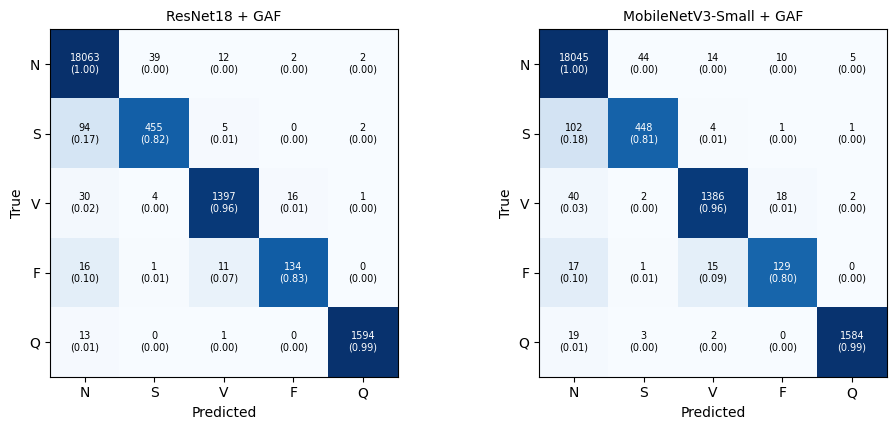

Saved: week3_confusion_resnet18_gaf.csv
Saved: week3_confusion_mobilenet_gaf.csv
Cocok dengan week2_confusion_mobilenet.csv: True


In [9]:
CM = {}
if BOTH_PRED:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
    for ax, m in zip(axes, MODELS):
        cm = confusion_matrix(PRED[m]["y_true"], PRED[m]["y_pred"], labels=range(NUM_CLASSES))
        CM[m] = cm
        cm_norm = cm / cm.sum(axis=1, keepdims=True)
        ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
        ax.set_title(m, fontsize=10)
        ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES)
        ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
        for i in range(NUM_CLASSES):
            for j in range(NUM_CLASSES):
                ax.text(j, i, f"{cm[i, j]}\n({cm_norm[i, j]:.2f})", ha="center", va="center", fontsize=7,
                        color="white" if cm_norm[i, j] > 0.5 else "black")
    plt.tight_layout()
    fig.savefig(week3_path(FIGURES_DIR, "week3_confusion_matrices.png"), dpi=150, bbox_inches="tight")
    plt.show()

    for m, fname in ((MODEL_R, "week3_confusion_resnet18_gaf.csv"), (MODEL_M, "week3_confusion_mobilenet_gaf.csv")):
        pd.DataFrame(CM[m], index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(week3_path(RESULTS_DIR, fname))
        print("Saved:", fname)

    if FOUND["w2_confusion"]:
        w2_cm = pd.read_csv(ARTIFACTS["w2_confusion"], index_col=0).to_numpy()
        print("Cocok dengan week2_confusion_mobilenet.csv:", bool(np.array_equal(w2_cm, CM[MODEL_M])))
    else:
        print("week2_confusion_mobilenet.csv:", NOT_FOUND)
else:
    print(NOT_FOUND)

# Section 10 — Per-class Analysis

Recall per kelas pada seluruh test set dan per fold (fold sama dengan Section 6). Fokus pada kelas minoritas **S** (supraventricular) dan **F** (fusion).

In [10]:
per_class_fold = None
if BOTH_PRED:
    overall_recall = pd.DataFrame(
        [{"Model": m, **{c: CM[m][i, i] / CM[m][i].sum() for i, c in enumerate(CLASS_NAMES)}} for m in MODELS])
    print("Recall per kelas — seluruh test set:")
    display(overall_recall.round(4))

    rows = []
    for k, idx in enumerate(FOLDS):
        for m in MODELS:
            rec = recall_score(PRED[m]["y_true"][idx], PRED[m]["y_pred"][idx], labels=range(NUM_CLASSES),
                               average=None, zero_division=0)
            rows.append({"Fold": k + 1, "Model": m, **dict(zip(CLASS_NAMES, rec))})
    per_class_fold = pd.DataFrame(rows)
    per_class_fold.to_csv(week3_path(RESULTS_DIR, "week3_per_class_recall_folds.csv"), index=False)
    print("Recall per kelas — per fold:")
    display(per_class_fold.round(4))

    print("Mean ± std recall per kelas antar fold:")
    display(per_class_fold.groupby("Model")[CLASS_NAMES].agg(["mean", "std"]).reindex(MODELS).round(4))

    # Kesalahan terbanyak untuk kelas minoritas (dari confusion matrix seluruh test set)
    for m in MODELS:
        for c in ("S", "F"):
            i = CLASS_NAMES.index(c)
            off = [(CLASS_NAMES[j], int(CM[m][i, j])) for j in range(NUM_CLASSES) if j != i]
            j_name, n = max(off, key=lambda t: t[1])
            print(f"{m:26s} kelas {c}: {CM[m][i].sum() - CM[m][i, i]} salah dari {CM[m][i].sum()}; "
                  f"terbanyak diprediksi sebagai {j_name} ({n})")
else:
    print(NOT_FOUND)

Recall per kelas — seluruh test set:


,Model,N,S,V,F,Q
0,ResNet18 + GAF,0.997,0.8183,0.9648,0.8272,0.9913
1,MobileNetV3-Small + GAF,0.996,0.8058,0.9572,0.7963,0.9851


Recall per kelas — per fold:


,Fold,Model,N,S,V,F,Q
0,1,ResNet18 + GAF,0.9975,0.7748,0.9483,0.8125,0.9783
1,1,MobileNetV3-Small + GAF,0.9964,0.7387,0.9276,0.7812,0.9783
2,2,ResNet18 + GAF,0.9967,0.8108,0.9724,0.9062,0.9907
3,2,MobileNetV3-Small + GAF,0.9983,0.8018,0.9586,0.8438,0.9876
4,3,ResNet18 + GAF,0.9967,0.8649,0.9619,0.8485,0.9969
5,3,MobileNetV3-Small + GAF,0.9967,0.8649,0.9689,0.8182,0.9844
6,4,ResNet18 + GAF,0.9972,0.8304,0.9758,0.7879,0.9969
7,4,MobileNetV3-Small + GAF,0.9956,0.8482,0.9723,0.7273,0.9875
8,5,ResNet18 + GAF,0.9967,0.8108,0.9655,0.7812,0.9938
9,5,MobileNetV3-Small + GAF,0.9928,0.7748,0.9586,0.8125,0.9876


Mean ± std recall per kelas antar fold:


N               S               V          \
                          mean     std    mean     std    mean     std   
Model                                                                    
ResNet18 + GAF           0.997  0.0004  0.8183  0.0329  0.9648  0.0107   
MobileNetV3-Small + GAF  0.996  0.0020  0.8057  0.0519  0.9572  0.0176   

                              F               Q          
                           mean     std    mean     std  
Model                                                    
ResNet18 + GAF           0.8273  0.0514  0.9913  0.0077  
MobileNetV3-Small + GAF  0.7966  0.0447  0.9851  0.0040

ResNet18 + GAF             kelas S: 101 salah dari 556; terbanyak diprediksi sebagai N (94)
ResNet18 + GAF             kelas F: 28 salah dari 162; terbanyak diprediksi sebagai N (16)
MobileNetV3-Small + GAF    kelas S: 108 salah dari 556; terbanyak diprediksi sebagai N (102)
MobileNetV3-Small + GAF    kelas F: 33 salah dari 162; terbanyak diprediksi sebagai N (17)


# Section 11 — Boxplot Recall per Kelas (5 fold)

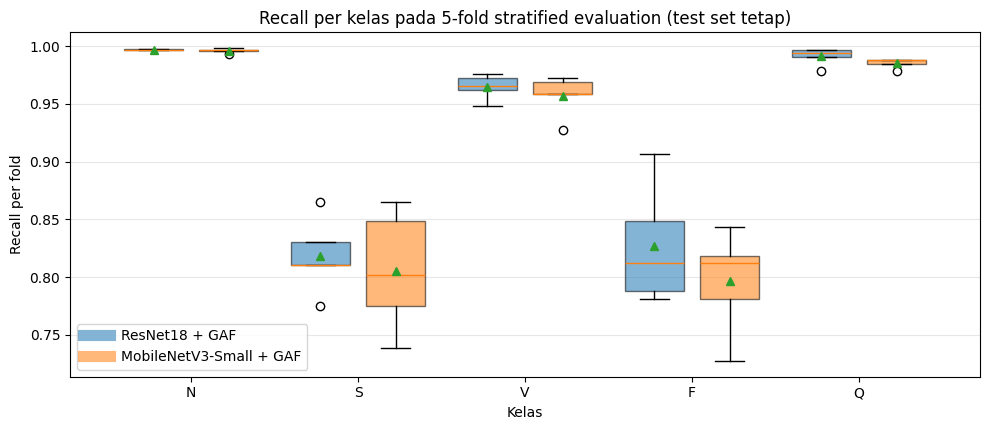

In [11]:
if per_class_fold is not None:
    fig, ax = plt.subplots(figsize=(10, 4.4))
    width, gap = 0.35, 0.2
    for k, m in enumerate(MODELS):
        data = [per_class_fold[per_class_fold["Model"] == m][c].to_numpy() for c in CLASS_NAMES]
        pos = np.arange(NUM_CLASSES) + (k - 0.5) * (width + gap / 2)
        bp = ax.boxplot(data, positions=pos, widths=width, patch_artist=True, showmeans=True)
        for box in bp["boxes"]:
            box.set_facecolor(COLORS[m]); box.set_alpha(0.55)
        ax.plot([], [], color=COLORS[m], lw=8, alpha=0.55, label=m)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES)
    ax.set_xlabel("Kelas"); ax.set_ylabel("Recall per fold")
    ax.set_title("Recall per kelas pada 5-fold stratified evaluation (test set tetap)")
    ax.grid(axis="y", alpha=0.3); ax.legend(loc="lower left")
    plt.tight_layout()
    fig.savefig(week3_path(FIGURES_DIR, "week3_per_class_boxplot.png"), dpi=150, bbox_inches="tight")
    plt.show()
else:
    print(NOT_FOUND)

# Section 12 — Learning Curves

Dari `history_gaf.csv` (Week 1) dan `week2_history_mobilenet.csv` (Week 2).

**Penting:** Week 1 dan Week 2 **tidak memiliki validation set terpisah**. "Test loss" dan "Test Macro F1" dihitung pada **test set** setiap epoch dan dipakai untuk memilih checkpoint terbaik. Kurva ini **bukan validation curve**; nilai pada epoch terbaik (garis putus-putus) cenderung optimistis.

ResNet18 + GAF             history: 25 epoch
MobileNetV3-Small + GAF    history: 25 epoch


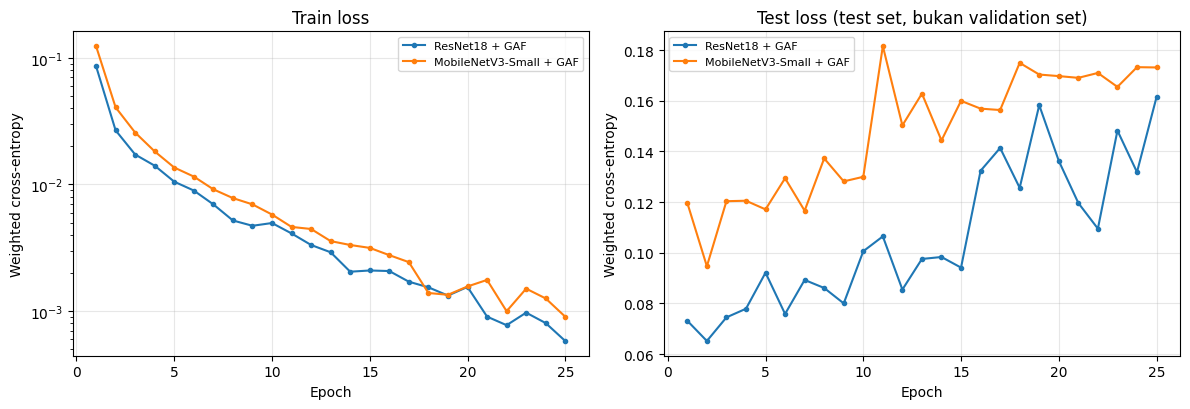

ResNet18 + GAF             Macro F1 tertinggi 0.9353 @ epoch 21 | epoch terakhir 0.9299 | train loss akhir 0.0006 | test loss min 0.0652 @ epoch 2, akhir 0.1615
MobileNetV3-Small + GAF    Macro F1 tertinggi 0.9211 @ epoch 24 | epoch terakhir 0.9160 | train loss akhir 0.0009 | test loss min 0.0947 @ epoch 2, akhir 0.1732


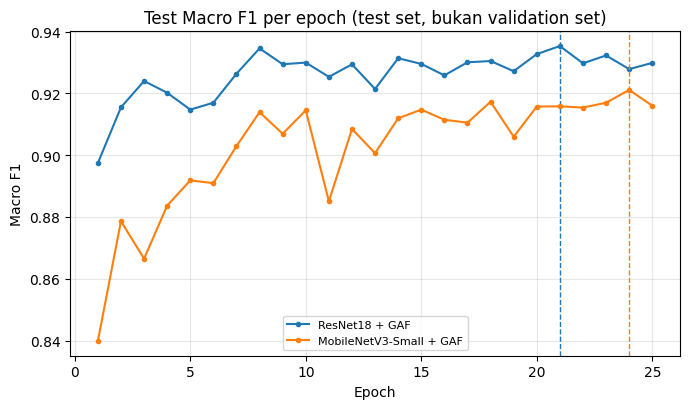

In [12]:
HIST = {}
for m, key in ((MODEL_R, "w1_history"), (MODEL_M, "w2_history")):
    HIST[m] = pd.read_csv(ARTIFACTS[key]) if FOUND[key] else None
    print(f"{m:26s} history: " + (NOT_FOUND if HIST[m] is None else f"{len(HIST[m])} epoch"))

curves = {m: h for m, h in HIST.items() if h is not None}
if curves:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for m, h in curves.items():
        axes[0].plot(h["epoch"], h["train_loss"], marker=".", color=COLORS[m], label=m)
        axes[1].plot(h["epoch"], h["test_loss"], marker=".", color=COLORS[m], label=m)
    axes[0].set_title("Train loss"); axes[1].set_title("Test loss (test set, bukan validation set)")
    for ax in axes:
        ax.set_xlabel("Epoch"); ax.set_ylabel("Weighted cross-entropy"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    axes[0].set_yscale("log")
    plt.tight_layout()
    fig.savefig(week3_path(FIGURES_DIR, "week3_loss_curve.png"), dpi=150, bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 4.2))
    for m, h in curves.items():
        ax.plot(h["epoch"], h["test_f1"], marker=".", color=COLORS[m], label=m)
        best = h.loc[h["test_f1"].idxmax()]
        ax.axvline(best["epoch"], color=COLORS[m], ls="--", lw=1)
        print(f"{m:26s} Macro F1 tertinggi {best['test_f1']:.4f} @ epoch {int(best['epoch'])} | "
              f"epoch terakhir {h['test_f1'].iloc[-1]:.4f} | train loss akhir {h['train_loss'].iloc[-1]:.4f} | "
              f"test loss min {h['test_loss'].min():.4f} @ epoch {int(h.loc[h['test_loss'].idxmin(), 'epoch'])}, "
              f"akhir {h['test_loss'].iloc[-1]:.4f}")
    ax.set_title("Test Macro F1 per epoch (test set, bukan validation set)")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Macro F1"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout()
    fig.savefig(week3_path(FIGURES_DIR, "week3_f1_curve.png"), dpi=150, bbox_inches="tight")
    plt.show()
else:
    print(NOT_FOUND)

# Section 13 — Complexity / Trade-off

Semua angka dibaca dari `week2_comparison.csv` (diukur di Week 2; waktu inferensi = batch sintetis 64 pada GPU yang sama, tanpa I/O). Waktu training ResNet18 tidak tercatat di Week 1 → `NOT RECORDED` (tidak diisi tebakan).

In [13]:
COMPLEXITY_COLS = ["Params total", "Params trainable", "Train time total (min)", "Train time / epoch (s)",
                   "Inference ms / batch64", "Inference ms / sample"]


def as_number(v):
    try:
        return float(v)
    except (TypeError, ValueError):
        return None


complexity = None
if w2_comparison is not None:
    rows = []
    for m in MODELS:
        r = w2_comparison[w2_comparison["Method"] == W2_LABEL[m]]
        rows.append({"Model": m, **({c: r.iloc[0][c] for c in COMPLEXITY_COLS} if len(r)
                                    else {c: NOT_FOUND for c in COMPLEXITY_COLS})})
    complexity = pd.DataFrame(rows)
    if fold_metrics is not None:
        complexity["Macro F1 (seluruh test set)"] = overall["Macro F1"].to_numpy()
    display(complexity)

    pr, pm = (as_number(complexity.loc[i, "Params total"]) for i in (0, 1))
    ir, im = (as_number(complexity.loc[i, "Inference ms / sample"]) for i in (0, 1))
    if pr and pm:
        print(f"Parameter MobileNet = {pm / pr:.1%} dari ResNet18 ({pr / pm:.1f}× lebih sedikit)")
    if ir and im:
        print(f"Waktu inferensi/sampel MobileNet = {im / ir:.1%} dari ResNet18 ({ir / im:.1f}× lebih cepat, GPU Week 2)")
    if as_number(complexity.loc[0, "Train time total (min)"]) is None:
        print("Waktu training ResNet18:", NOT_RECORDED, "→ perbandingan waktu training tidak dapat dilakukan.")
else:
    print(NOT_FOUND, "week2_comparison.csv")

,Model,Params total,Params trainable,Train time total (min),Train time / epoch (s),Inference ms / batch64,Inference ms / sample,Macro F1 (seluruh test set)
0,ResNet18 + GAF,11341125,10658053,NOT RECORDED,NOT RECORDED,51.028120,0.797314,0.935315
1,MobileNetV3-Small + GAF,1522981,1512493,322.0406101226807,772.8974642944336,13.744352,0.214756,0.921126


Parameter MobileNet = 13.4% dari ResNet18 (7.4× lebih sedikit)
Waktu inferensi/sampel MobileNet = 26.9% dari ResNet18 (3.7× lebih cepat, GPU Week 2)
Waktu training ResNet18: NOT RECORDED → perbandingan waktu training tidak dapat dilakukan.


In [14]:
SUMMARY_CSV = week3_path(RESULTS_DIR, "week3_summary.csv")
summary_rows = []
for i, m in enumerate(MODELS):
    row = {"Model": m}
    for c in METRIC_COLS:
        row[f"overall_{c}"] = overall.loc[i, c]
        if fold_metrics is not None:
            v = fold_metrics[fold_metrics["Model"] == m][c]
            row[f"fold_mean_{c}"], row[f"fold_std_{c}"] = v.mean(), v.std()
    if per_class_fold is not None:
        for j, c in enumerate(CLASS_NAMES):
            row[f"overall_recall_{c}"] = CM[m][j, j] / CM[m][j].sum()
    if complexity is not None:
        for c in COMPLEXITY_COLS:
            row[c] = complexity.loc[i, c]
    row["checkpoint_epoch"] = overall.loc[i, "Checkpoint epoch"]
    summary_rows.append(row)
summary = pd.DataFrame(summary_rows)
summary.to_csv(SUMMARY_CSV, index=False)
display(summary.T)
print("Saved:", SUMMARY_CSV)

,0,1
Model,ResNet18 + GAF,MobileNetV3-Small + GAF
overall_Accuracy,0.988626,0.986296
fold_mean_Accuracy,0.988626,0.986296
fold_std_Accuracy,0.001726,0.003197
overall_Macro Precision,0.952308,0.935326
fold_mean_Macro Precision,0.952922,0.938403
fold_std_Macro Precision,0.012661,0.029375
overall_Macro Recall,0.919709,0.908056
fold_mean_Macro Recall,0.919729,0.908103
fold_std_Macro Recall,0.014608,0.015905


Saved: /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion/outputs/results/week3_summary.csv


# Section 14 — Interpretasi

Jawaban di bawah **dihasilkan dari angka** pada Section 4–13 (tidak ada nilai yang ditulis tangan). Aturan: ambang "sebanding" ≤ 1,0 poin persen Macro F1 (deskriptif), α = 0,05 untuk paired t-test. Pernyataan bersifat deskriptif; eksperimen ini **tidak** memisahkan penyebab perbedaan (arsitektur, bagian yang dilatih, LR, dan head berbeda sekaligus — deviasi D1–D3 Week 2).

In [15]:
ANSWERS = {}
if fold_metrics is None or ttest is None:
    print(NOT_FOUND, "— interpretasi memerlukan prediksi kedua model.")
else:
    f1_r, f1_m = overall.loc[0, "Macro F1"], overall.loc[1, "Macro F1"]
    diff_pp = (f1_m - f1_r) * 100
    t_f1 = ttest[ttest["Metric"] == "Macro F1"].iloc[0]
    t_acc = ttest[ttest["Metric"] == "Accuracy"].iloc[0]
    n_r_better = int(t_f1["Folds ResNet18 > MobileNet"])
    fold_diff = (fold_metrics[fold_metrics["Model"] == MODEL_M].sort_values("Fold")["Macro F1"].to_numpy()
                 - fold_metrics[fold_metrics["Model"] == MODEL_R].sort_values("Fold")["Macro F1"].to_numpy()) * 100

    ANSWERS["1_setara"] = (
        f"Macro F1 seluruh test set: ResNet18 {f1_r:.4f}, MobileNet {f1_m:.4f} (selisih {diff_pp:+.2f} pp). "
        + (f"|selisih| ≤ {EQUIV_PP} pp → sebanding menurut ambang deskriptif."
           if abs(diff_pp) <= EQUIV_PP else
           f"|selisih| > {EQUIV_PP} pp → tidak memenuhi ambang 'sebanding'; "
           + ("MobileNet lebih rendah." if diff_pp < 0 else "MobileNet lebih tinggi.")))
    ANSWERS["2_konsisten"] = (
        f"Selisih Macro F1 per fold (MobileNet − ResNet18, pp): {np.round(fold_diff, 2).tolist()}. "
        f"ResNet18 lebih tinggi pada {n_r_better}/{N_FOLDS} fold; std selisih {fold_diff.std(ddof=1):.2f} pp. "
        + ("Arah selisih konsisten di semua fold." if n_r_better in (0, N_FOLDS) else "Arah selisih tidak konsisten antar fold."))
    ANSWERS["3_ttest"] = (
        f"Macro F1: t = {t_f1['t-statistic']:.3f}, p = {t_f1['p-value']:.4f}; "
        f"Accuracy: t = {t_acc['t-statistic']:.3f}, p = {t_acc['p-value']:.4f} (α = {ALPHA}). "
        + ("Macro F1: p < α → ada bukti perbedaan pada 5 fold evaluasi ini" if t_f1["reject_H0"]
           else "Macro F1: p ≥ α → tidak ada bukti perbedaan pada 5 fold evaluasi ini")
        + "; dengan hanya 5 pasangan dari satu test set dan satu run per model, ini bukti lemah dan tidak menggeneralisasi ke data/seed lain.")
    hardest = {}
    for m in MODELS:
        rec = {c: CM[m][i, i] / CM[m][i].sum() for i, c in enumerate(CLASS_NAMES)}
        hardest[m] = min(rec, key=rec.get)
        std_fold = per_class_fold[per_class_fold["Model"] == m][hardest[m]].std()
        ANSWERS[f"4_kelas_sulit_{m}"] = (
            f"{m}: recall terendah kelas {hardest[m]} ({rec[hardest[m]]:.4f}, std antar fold {std_fold:.4f}); "
            f"S = {rec['S']:.4f}, F = {rec['F']:.4f}.")
    if complexity is not None and as_number(complexity.loc[0, "Params total"]) and as_number(complexity.loc[1, "Params total"]):
        pr, pm = as_number(complexity.loc[0, "Params total"]), as_number(complexity.loc[1, "Params total"])
        ir, im = as_number(complexity.loc[0, "Inference ms / sample"]), as_number(complexity.loc[1, "Inference ms / sample"])
        ANSWERS["5_tradeoff"] = (
            f"MobileNet memakai {pm / pr:.1%} parameter ResNet18 ({pr / pm:.1f}× lebih sedikit)"
            + (f" dan {ir / im:.1f}× lebih cepat per sampel saat inferensi (GPU Week 2)" if ir and im else "")
            + f", dengan selisih Macro F1 {diff_pp:+.2f} pp.")
    else:
        ANSWERS["5_tradeoff"] = f"{NOT_FOUND}: data kompleksitas tidak tersedia."
    ANSWERS["6_layak"] = (
        "Jika efisiensi (memori/latensi) lebih penting, MobileNet dapat dipertimbangkan dengan menerima penurunan "
        f"Macro F1 {abs(diff_pp):.2f} pp pada test set ini"
        + (" — perlu dicek apakah penurunan recall kelas minoritas (S/F) dapat diterima untuk penggunaannya."
           if diff_pp < 0 else ".")
        + " Keputusan ini adalah penilaian kebutuhan, bukan hasil uji statistik.")
    for k, v in ANSWERS.items():
        print(f"[{k}] {v}\n")

[1_setara] Macro F1 seluruh test set: ResNet18 0.9353, MobileNet 0.9211 (selisih -1.42 pp). |selisih| > 1.0 pp → tidak memenuhi ambang 'sebanding'; MobileNet lebih rendah.

[2_konsisten] Selisih Macro F1 per fold (MobileNet − ResNet18, pp): [-2.65, -0.65, -0.39, -1.16, -2.01]. ResNet18 lebih tinggi pada 5/5 fold; std selisih 0.95 pp. Arah selisih konsisten di semua fold.

[3_ttest] Macro F1: t = -3.236, p = 0.0318; Accuracy: t = -2.835, p = 0.0471 (α = 0.05). Macro F1: p < α → ada bukti perbedaan pada 5 fold evaluasi ini; dengan hanya 5 pasangan dari satu test set dan satu run per model, ini bukti lemah dan tidak menggeneralisasi ke data/seed lain.

[4_kelas_sulit_ResNet18 + GAF] ResNet18 + GAF: recall terendah kelas S (0.8183, std antar fold 0.0329); S = 0.8183, F = 0.8272.

[4_kelas_sulit_MobileNetV3-Small + GAF] MobileNetV3-Small + GAF: recall terendah kelas F (0.7963, std antar fold 0.0447); S = 0.8058, F = 0.7963.

[5_tradeoff] MobileNet memakai 13.4% parameter ResNet18 (7.4× lebi

# Section 15 — Kesimpulan

### Hasil eksperimen
Angka di sel bawah ini (dari Section 4, 7, 8, 10, 13).

### Interpretasi
- Perbandingan memakai Macro F1 dan ambang deskriptif 1,0 pp yang ditetapkan sebelum melihat hasil; jawaban per pertanyaan ada di Section 14.
- Hasil p-value dibaca sebagai indikasi variasi metrik antar subset test set, bukan sebagai bukti bahwa satu arsitektur lebih baik secara umum.
- Penyebab perbedaan (arsitektur vs bagian yang dilatih vs LR vs head) **tidak dapat dipisahkan** dari eksperimen ini.

### Keterbatasan
1. **Satu model dilatih sekali** sebelum folded evaluation; tidak ada variasi data latih atau inisialisasi.
2. **Fold hanya untuk evaluasi** — 5 subset dari test set tetap, bukan cross-validation; variasi antar fold hanya mencerminkan variasi sampel uji.
3. **Satu seed** (42) per model; variansi antar run tidak diketahui.
4. **Test set sudah dipakai** di Week 1/Week 2 untuk monitoring dan seleksi checkpoint (tidak ada validation set) → metrik cenderung optimistis, dan kurva di Section 12 bukan validation curve.
5. **Paired t-test hanya 5 pasangan observasi** yang berasal dari satu test set → daya uji rendah dan observasi tidak independen dari proses seleksi checkpoint.
6. Kelas F (162 sampel; ~32 per fold) dan S (556; ~111 per fold) kecil → recall per fold kelas ini sangat berfluktuasi.
7. Waktu training ResNet18 tidak tercatat di Week 1 → trade-off waktu training tidak dapat dibandingkan.

In [16]:
if fold_metrics is not None and ttest is not None:
    print("HASIL EKSPERIMEN")
    for i, m in enumerate(MODELS):
        fm = fold_metrics[fold_metrics["Model"] == m]
        print(f"- {m}: Macro F1 seluruh test set {overall.loc[i, 'Macro F1']:.4f}, Accuracy {overall.loc[i, 'Accuracy']:.4f}; "
              f"5 fold: Macro F1 {fm['Macro F1'].mean():.4f} ± {fm['Macro F1'].std():.4f}")
    for _, r in ttest[ttest["Metric"].isin(["Macro F1", "Accuracy"])].iterrows():
        print(f"- Paired t-test {r['Metric']}: selisih rata-rata {r['Mean difference (MobileNet - ResNet18)']:+.4f}, "
              f"t = {r['t-statistic']:.3f}, p = {r['p-value']:.4f} → {r['Keputusan']} (α = {ALPHA})")
    for m in MODELS:
        print("- " + ANSWERS[f"4_kelas_sulit_{m}"])
    print("- " + ANSWERS["5_tradeoff"])
else:
    print(NOT_FOUND)

HASIL EKSPERIMEN
- ResNet18 + GAF: Macro F1 seluruh test set 0.9353, Accuracy 0.9886; 5 fold: Macro F1 0.9353 ± 0.0125
- MobileNetV3-Small + GAF: Macro F1 seluruh test set 0.9211, Accuracy 0.9863; 5 fold: Macro F1 0.9216 ± 0.0218
- Paired t-test Macro F1: selisih rata-rata -0.0137, t = -3.236, p = 0.0318 → p < α: ada bukti perbedaan (α = 0.05)
- Paired t-test Accuracy: selisih rata-rata -0.0023, t = -2.835, p = 0.0471 → p < α: ada bukti perbedaan (α = 0.05)
- ResNet18 + GAF: recall terendah kelas S (0.8183, std antar fold 0.0329); S = 0.8183, F = 0.8272.
- MobileNetV3-Small + GAF: recall terendah kelas F (0.7963, std antar fold 0.0447); S = 0.8058, F = 0.7963.
- MobileNet memakai 13.4% parameter ResNet18 (7.4× lebih sedikit) dan 3.7× lebih cepat per sampel saat inferensi (GPU Week 2), dengan selisih Macro F1 -1.42 pp.


# Section 16 — Experiment Log

Ditulis ke `outputs/results/week3_experiment_log.json`. Sel ini juga memeriksa bahwa **tidak ada file Week 1/Week 2 yang berubah** dan mencantumkan semua output Week 3.

In [17]:
prior_after = snapshot_existing()
changed = sorted(p for p, v in PRIOR_SNAPSHOT.items() if prior_after.get(p) != v)
new_non_week3 = sorted(set(prior_after) - set(PRIOR_SNAPSHOT))
prior_unchanged = not changed and not new_non_week3

LOG_JSON = week3_path(RESULTS_DIR, "week3_experiment_log.json")
WEEK3_OUTPUTS = sorted(
    {os.path.relpath(os.path.join(d, n), BASE_DIR)
     for d in (RESULTS_DIR, FIGURES_DIR) if os.path.isdir(d)
     for n in os.listdir(d) if n.startswith("week3_")} | {os.path.relpath(LOG_JSON, BASE_DIR)})

experiment_log = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "notebook": "03_hasil_analisis.ipynb",
    "RUN_NEW_TRAINING": RUN_NEW_TRAINING,
    "training_performed": False,
    "inference_performed": False,
    "environment": {"python": sys.version.split()[0], "platform": platform.platform(), "numpy": np.__version__,
                    "pandas": pd.__version__, "scipy": scipy.__version__, "scikit-learn": sklearn.__version__,
                    "matplotlib": matplotlib.__version__, "torch": torch.__version__ if torch is not None else None},
    "models": {MODEL_R: "Week 1 baseline", MODEL_M: "Week 2 pembanding terbaik"},
    "artifacts_used": {k: {"path": os.path.relpath(p, BASE_DIR), "found": FOUND[k]} for k, p in ARTIFACTS.items()},
    "checkpoint_epochs": {m: (PRED[m]["epoch"] if PRED[m] is not None else NOT_FOUND) for m in MODELS},
    "evaluation": {
        "method": "5-fold stratified evaluation pada fixed test set (bukan cross-validation; tanpa training ulang)",
        "splitter": f"StratifiedKFold(n_splits={N_FOLDS}, shuffle=True, random_state={SEED})",
        "fold_sizes": [int(len(i)) for i in FOLDS],
        "metrics": METRIC_COLS, "average": "macro", "zero_division": 0,
    },
    "significance_test": {"test": "scipy.stats.ttest_rel (two-sided)", "pairs": N_FOLDS, "alpha": ALPHA,
                          "difference": "MobileNet - ResNet18",
                          "results": ttest.to_dict(orient="records") if ttest is not None else NOT_FOUND},
    "equivalence_threshold_pp": EQUIV_PP,
    "interpretation": ANSWERS,
    "limitations": [
        "Satu model dilatih sekali sebelum folded evaluation",
        "Fold hanya untuk evaluasi (subset test set tetap)",
        "Satu seed (42)",
        "Test set dipakai di Week 1/2 untuk monitoring dan seleksi checkpoint (tanpa validation set)",
        "Paired t-test hanya 5 pasangan observasi",
        "Waktu training ResNet18 tidak tercatat di Week 1",
    ],
    "week3_outputs": WEEK3_OUTPUTS,
    "week1_week2_artifacts_unchanged": prior_unchanged,
}

with open(LOG_JSON, "w") as fh:
    json.dump(experiment_log, fh, indent=2, default=str)

print("Saved:", LOG_JSON)
print("Output Week 3:")
for p in WEEK3_OUTPUTS:
    print("  ", p)
print("Artifact Week 1/Week 2 tidak berubah:", prior_unchanged)
if not prior_unchanged:
    raise RuntimeError(f"File Week 1/2 berubah atau bertambah: {changed + new_non_week3}")

Saved: /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion/outputs/results/week3_experiment_log.json
Output Week 3:
   outputs/figures/week3_confusion_matrices.png
   outputs/figures/week3_f1_curve.png
   outputs/figures/week3_loss_curve.png
   outputs/figures/week3_per_class_boxplot.png
   outputs/results/week3_confusion_mobilenet_gaf.csv
   outputs/results/week3_confusion_resnet18_gaf.csv
   outputs/results/week3_experiment_log.json
   outputs/results/week3_fold_metrics.csv
   outputs/results/week3_paired_ttest.csv
   outputs/results/week3_per_class_recall_folds.csv
   outputs/results/week3_summary.csv
Artifact Week 1/Week 2 tidak berubah: True
